In [1]:
import pandas as pd
import numpy as np
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
export_dir = os.getcwd()
from pathlib import Path
import pickle
from collections import defaultdict
import time
import torch
import torch.nn as nn
import copy
import torch.nn.functional as F
import optuna
import logging
import matplotlib.pyplot as plt
import ipynb
import importlib
import sys
from tqdm import tqdm
import multiprocessing
from functools import partial
from concurrent.futures import ProcessPoolExecutor
import torch.multiprocessing as mp
from openpyxl.cell.cell import MergedCell

In [2]:
data_name = "ML1M" ### Can be ML1M, Yahoo, Pinterest
recommender_name = "MLP" ### Can be MLP, VAE, NCF

DP_DIR = Path("data", data_name) 
export_dir = Path(os.getcwd())
files_path = Path(export_dir, DP_DIR)
checkpoints_path = Path(export_dir, "checkpoints")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
expl_names=['lxr', 'accent', 'cosine']

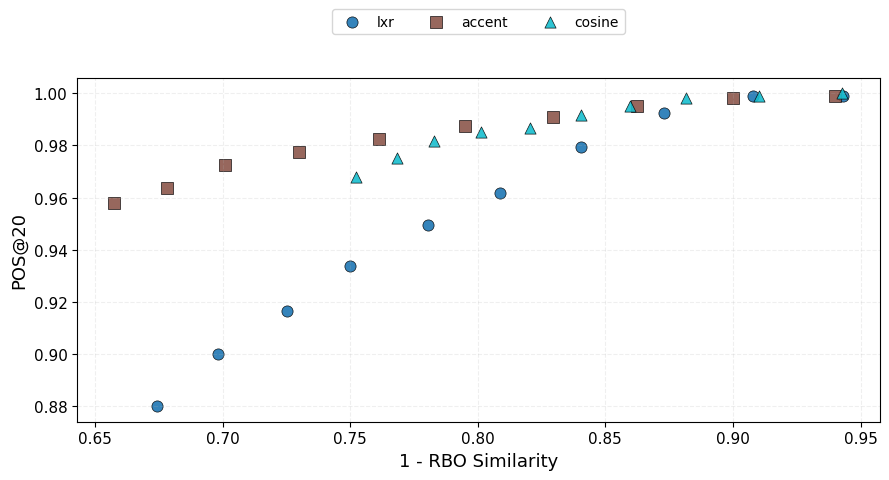

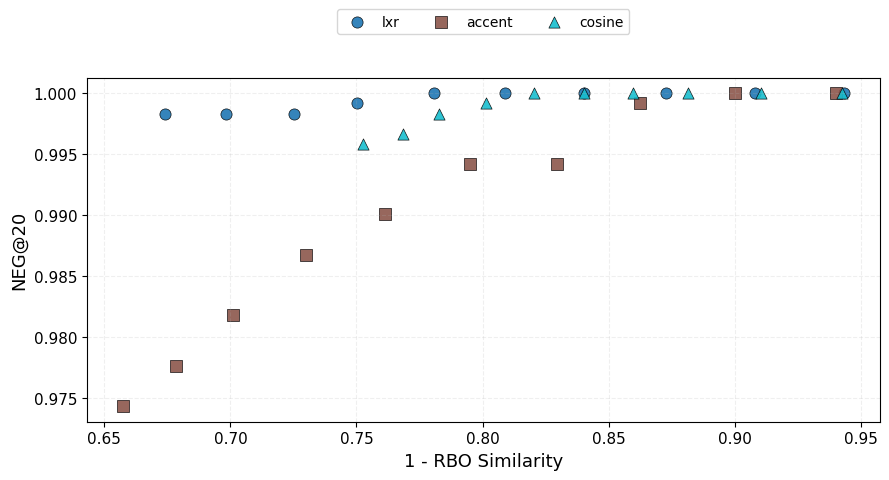

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load metrics for all explanation models
all_metrics = {}

for name in expl_names:
    all_metrics[name] = pd.read_pickle(
        Path(files_path, f'{recommender_name}_{name}_metrics.pkl')
    )

# 2. Define markers and colors
markers = ['o', 's', '^', 'D', 'P', 'X', '*', 'v', '<', '>']
colors = plt.cm.tab10(np.linspace(0, 1, len(expl_names)))

# 3. Generate two separate figures
for metric in ['POS_at_20', 'NEG_at_20']:

    fig, ax = plt.subplots(figsize=(9, 5))

    for i, name in enumerate(expl_names):

        metrics = all_metrics[name]

        x = 1 - np.asarray(metrics['RBO_SIM'])
        y = np.asarray(metrics[metric])

        ax.scatter(
            x, y,
            label=name,
            color=colors[i],
            marker=markers[i % len(markers)],
            s=65,
            alpha=0.9,
            edgecolors='black',
            linewidths=0.5
        )

    ax.set_xlabel('1 - RBO Similarity', fontsize=13)
    ax.set_ylabel(metric.replace('_at_', '@'), fontsize=13)

    ax.tick_params(axis='both', labelsize=11)
    ax.grid(alpha=0.2, linestyle='--')

    ax.legend(
        loc='upper center',
        bbox_to_anchor=(0.5, 1.22),
        ncol=4,
        fontsize=10,
        frameon=True
    )

    plt.tight_layout()

    # Save as PDF and PNG
    fig.savefig(
        Path(files_path, f'{recommender_name}_{metric}_vs_RBO.pdf'),
        bbox_inches='tight'
    )

    fig.savefig(
        Path(files_path, f'{recommender_name}_{metric}_vs_RBO.png'),
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

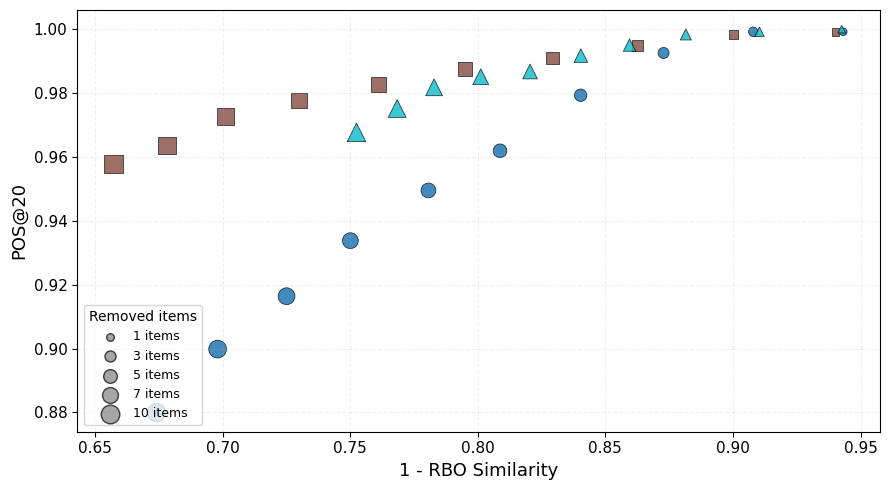

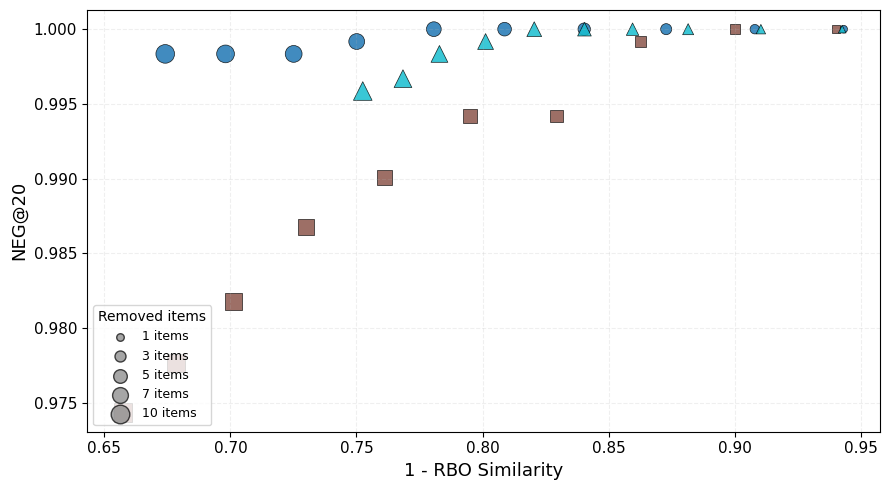

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load metrics for all explanation models
all_metrics = {}

for name in expl_names:
    all_metrics[name] = pd.read_pickle(
        Path(files_path, f'{recommender_name}_{name}_metrics.pkl')
    )

markers = ['o', 's', '^', 'D', 'P', 'X', '*', 'v', '<', '>']
colors = plt.cm.tab10(np.linspace(0, 1, len(expl_names)))

# Marker sizes for 1 to 10 removed items
min_size = 30
max_size = 180

for metric in ['POS_at_20', 'NEG_at_20']:

    fig, ax = plt.subplots(figsize=(9, 5))

    for i, name in enumerate(expl_names):

        metrics = all_metrics[name]

        x = 1 - np.asarray(metrics['RBO_SIM'])
        y = np.asarray(metrics[metric])

        # Number of removed items: 1, 2, ..., 10
        n_removed = np.arange(1, len(x) + 1)

        # Increase marker size with number of removed items
        sizes = np.linspace(min_size, max_size, len(x))

        ax.scatter(
            x, y,
            s=sizes,
            label=name,
            color=colors[i],
            marker=markers[i % len(markers)],
            alpha=0.85,
            edgecolors='black',
            linewidths=0.5
        )

    ax.set_xlabel('1 - RBO Similarity', fontsize=13)
    ax.set_ylabel(metric.replace('_at_', '@'), fontsize=13)

    ax.tick_params(axis='both', labelsize=11)
    ax.grid(alpha=0.2, linestyle='--')

    # Legend for explanation models
    model_legend = ax.legend(
        loc='upper center',
        bbox_to_anchor=(0.5, 1.22),
        ncol=4,
        fontsize=10,
        frameon=True
    )
    ax.add_artist(model_legend)

    # Separate legend for number of removed items
    size_values = [1, 3, 5, 7, 10]
    size_handles = [
        ax.scatter(
            [], [],
            s=min_size + (n - 1) / 9 * (max_size - min_size),
            color='gray',
            edgecolors='black',
            alpha=0.7,
            label=f'{n} items'
        )
        for n in size_values
    ]

    ax.legend(
        handles=size_handles,
        title='Removed items',
        loc='lower left',
        fontsize=9,
        title_fontsize=10
    )

    plt.tight_layout()

    fig.savefig(
        Path(files_path, f'{recommender_name}_{metric}_vs_RBO.pdf'),
        bbox_inches='tight'
    )

    plt.show()

In [13]:
s = "abca"
for i, c in enumerate(s):
    print(s[:-i])
    


abc
ab
a


In [19]:
Size(s)

NameError: name 'Size' is not defined

In [25]:
sorted(s)

['a', 'a', 'b', 'c']

In [ ]:
'bca'[[]

'a'

In [ ]:
S = "lee(t(c)o)de)"
for i, s in enumerate(S):
    if s in ['(', ')']:
        if s == '(':

Index: 0, Character: l
Index: 1, Character: e
Index: 2, Character: e
Index: 3, Character: (
Index: 4, Character: t
Index: 5, Character: (
Index: 6, Character: c
Index: 7, Character: )
Index: 8, Character: o
Index: 9, Character: )
Index: 10, Character: d
Index: 11, Character: e
Index: 12, Character: )
